# Preparing - Load library `aleph`

## Load library

In [19]:
import os
import sys
import random
import time
import math
import h5py
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import scipy as sp
import scanpy as sc
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

sys.path.append(os.path.abspath('..'))

## Config the params of notebook

In [20]:
BASE_DIR = '../../data'
dataset = 'QS_Diaphragm'
TOPO_WEIGHT = 40

class Config:
    cuda = True
    seed = 1234
    epoch = 2
    select_gene = 2000
    batch_size = 64
    dropout = 0.9
    lr = 0.01
    m = 0.5
    noise = 0.1
    temperature = 0.07
    enc_1 = 200
    enc_2 = 40
    enc_3 = 60
    mlp_dim = 40
    cluster_methods = ["KMeans"]

args = Config()

# Set device
device = torch.device('cuda:0' if (torch.cuda.is_available() and args.cuda) else 'cpu')

## Prepare device and load data

In [21]:
from utils.preprocessing import normalize

# --- Utilities ---
def get_device(use_cpu):
    if use_cpu is None:
        if torch.cuda.is_available():
            device = torch.device('cuda:0')
        else:
            device = torch.device('cpu')
    else:
        device = torch.device('cpu')
    return device
    
def preprocess(gene_exp, select_genes):
    X = np.ceil(gene_exp).astype(np.float32) 
    
    print(f"Original shape: {X.shape}, keeping {select_genes} genes")
    adata = sc.AnnData(X)

    adata = normalize(adata, copy=True, highly_genes=select_genes,
                             size_factors=True, normalize_input=True, logtrans_input=True)
    
    X = adata.X.astype(np.float32)
    return X

def adjust_learning_rate(optimizer, epoch, lr):
    eta_min = lr * (0.1 ** 3)
    new_lr = eta_min + (lr - eta_min) * (1 + math.cos(math.pi * epoch / 500)) / 2
    for param_group in optimizer.param_groups:
        param_group['lr'] = new_lr
    return lr

def save_model(name, model, optimizer, current_epoch, pre_epoch):
    save_dir = os.path.join(os.getcwd(), "save", name)
    os.makedirs(save_dir, exist_ok=True)
    if pre_epoch != -1:
        pre_path = os.path.join(save_dir, "checkpoint_{}.tar".format(pre_epoch))
        if os.path.exists(pre_path):
            os.remove(pre_path)
            
    cur_path = os.path.join(save_dir, "checkpoint_{}.tar".format(current_epoch))
    state = {'net': model.state_dict(), 'optimizer': optimizer.state_dict(), 'epoch': current_epoch}
    torch.save(state, cur_path)

def cluster_embedding(embedding, cluster_number, real_label, save_pred=False, cluster_methods=None):
    if cluster_methods is None: cluster_methods = ["KMeans"]
    result = {"t_clust": time.time()}
    if "KMeans" in cluster_methods:
        kmeans = KMeans(n_init=cluster_number, init="k-means++", random_state=0)
        pred = kmeans.fit_predict(embedding)
        if real_label is not None:
            result["ari"] = round(adjusted_rand_score(real_label, pred), 4)
            result["nmi"] = round(normalized_mutual_info_score(real_label, pred), 4)
        result["t_k"] = time.time()
        if save_pred: result["pred"] = pred
    return result

# --- Losses ---
class InstanceLoss(nn.Module):
    def __init__(self, temperature):
        super(InstanceLoss, self).__init__()
        self.temperature = temperature
        self.criterion = nn.CrossEntropyLoss(reduction="sum")

    def mask_correlated_samples(self, batch_size):
        N = 2 * batch_size
        mask = torch.ones((N, N)).fill_diagonal_(0)
        for i in range(batch_size):
            mask[i, batch_size + i] = 0
            mask[batch_size + i, i] = 0
        return mask.bool()

    def forward(self, features):
        self.batch_size = features.shape[0]
        self.mask = self.mask_correlated_samples(self.batch_size).to(device)
        N = 2 * self.batch_size
        contrast_feature = torch.cat(torch.unbind(features, dim=1), dim=0)

        sim = torch.matmul(contrast_feature, contrast_feature.T) / self.temperature
        sim_i_j = torch.diag(sim, self.batch_size)
        sim_j_i = torch.diag(sim, -self.batch_size)
        
        positive_samples = torch.cat((sim_i_j, sim_j_i), dim=0).reshape(N, 1)
        negative_samples = sim[self.mask].reshape(N, -1)

        labels = torch.zeros(N).to(positive_samples.device).long()
        logits = torch.cat((positive_samples, negative_samples), dim=1)

        loss = self.criterion(logits, labels) / N
        return loss

class ClusterLoss(nn.Module):
    def __init__(self, class_num, temperature):
        super(ClusterLoss, self).__init__()
        self.class_num = class_num
        self.temperature = temperature
        self.mask = self.mask_correlated_clusters(class_num)
        self.criterion = nn.CrossEntropyLoss(reduction="sum")

    def mask_correlated_clusters(self, class_num):
        N = 2 * class_num
        mask = torch.ones((N, N)).fill_diagonal_(0)
        for i in range(class_num):
            mask[i, class_num + i] = 0
            mask[class_num + i, i] = 0
        return mask.bool()

    def forward(self, features_cluster):
        c_i, c_j = torch.unbind(features_cluster, dim=1)
        p_i = c_i.sum(0).view(-1)
        p_i /= p_i.sum()
        ne_i = math.log(p_i.size(0)) + (p_i * torch.log(p_i + 1e-8)).sum()
        
        p_j = c_j.sum(0).view(-1)
        p_j /= p_j.sum()
        ne_j = math.log(p_j.size(0)) + (p_j * torch.log(p_j + 1e-8)).sum()
        ne_loss = ne_i + ne_j

        N = 2 * self.class_num
        cluster_feature = torch.cat(torch.unbind(features_cluster, dim=1), dim=0)
        cluster_feature = torch.nn.functional.normalize(cluster_feature, p=2, dim=1)
        sim = torch.matmul(cluster_feature, cluster_feature.T) / self.temperature
        sim_i_j = torch.diag(sim, self.class_num)
        sim_j_i = torch.diag(sim, -self.class_num)

        positive_clusters = torch.cat((sim_i_j, sim_j_i), dim=0).reshape(N, 1)
        negative_clusters = sim[self.mask].reshape(N, -1)

        labels = torch.zeros(N).to(positive_clusters.device).long()
        logits = torch.cat((positive_clusters, negative_clusters), dim=1)
        loss = self.criterion(logits, labels) / N

        return loss + ne_loss

In [22]:
class DataAug(nn.Module):
    def __init__(self, dropout=0.9):
        super(DataAug, self).__init__()
        self.drop = nn.Dropout(p=dropout)

    def forward(self, x):
        return self.drop(x)

class BaseEncoder(nn.Module):
    def __init__(self, dims):
        super(BaseEncoder, self).__init__()
        self.dims = dims
        enc = [nn.Linear(self.dims[0], self.dims[1]), nn.BatchNorm1d(self.dims[1]), nn.ReLU(),
               nn.Linear(self.dims[1], self.dims[2]), nn.BatchNorm1d(self.dims[2]), nn.ReLU(),
               nn.Linear(self.dims[2], self.dims[3]), nn.BatchNorm1d(self.dims[3]), nn.ReLU()]
        self.encoder = nn.Sequential(*enc)
        self._reset_prams()

    def _reset_prams(self):
        for m in self.modules():
            if isinstance(m, nn.Linear):
                nn.init.xavier_uniform_(m.weight)

    def forward(self, x):
        latent_out = self.encoder(x)
        return F.normalize(latent_out, dim=1)

class MLP(nn.Module):
    def __init__(self, contrastive_dim, mlp_dim, dim):
        super(MLP, self).__init__()
        self.encoder = nn.Sequential(
            nn.Linear(contrastive_dim, mlp_dim),
            nn.ReLU(),
            nn.Linear(mlp_dim, dim),
        )

    def forward(self, x):
        return self.encoder(x)

class ScCCL(nn.Module):
    def __init__(self, encoder_q, encoder_k, instance_projector, cluster_projector, class_num, m=0.2):
        super(ScCCL, self).__init__()
        self.m = m
        self.encoder_q = encoder_q
        self.encoder_k = encoder_k
        
        for param_q, param_k in zip(self.encoder_q.parameters(), self.encoder_k.parameters()):
            param_k.data.copy_(param_q.data)
            param_k.requires_grad = False

        self.instance_projector = instance_projector
        self.cluster_projector = nn.Sequential(cluster_projector, nn.Softmax(dim=1))

    @torch.no_grad()
    def _momentum_update_key_encoder(self):
        for param_q, param_k in zip(self.encoder_q.parameters(), self.encoder_k.parameters()):
            param_k.data = param_k.data * self.m + param_q.data * (1. - self.m)

    def forward(self, cell_q, cell_k):
        q = self.encoder_q(cell_q)
        q_instance = F.normalize(self.instance_projector(q), dim=1)
        q_cluster = self.cluster_projector(q)

        if cell_k is None:
            return q_instance, q_cluster, None, None

        with torch.no_grad():
            self._momentum_update_key_encoder()
            k = self.encoder_k(cell_k)
            k_instance = F.normalize(self.instance_projector(k), dim=1)
            k_cluster = self.cluster_projector(k)

        return q_instance, q_cluster, k_instance, k_cluster

In [23]:
from sklearn.decomposition import PCA
from topology_signature import TopologySignatureLoss

# --- Main ScCCL Training Logic ---
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

# EPOCH_NOTIFY_EVERY = 10
EPOCH_NOTIFY_EVERY = 50

def run(gene_exp, cluster_number, dataset, real_label, epochs, lr, temperature, dropout, layers, batch_size, m,
        save_pred=True, noise=None, use_cpu=None, cluster_methods=None, topo_weight=40.0):
    if cluster_methods is None:
        cluster_methods = []
    results = {}

    start = time.time()
    embedding, best_model, model = train_model(gene_exp=gene_exp, cluster_number=cluster_number, real_label=real_label,
                                        epochs=epochs, lr=lr, temperature=temperature,
                                        dropout=dropout, layers=layers, batch_size=batch_size,
                                        m=m, save_pred=save_pred, noise=noise, use_cpu=use_cpu, topo_weight=topo_weight)

    if save_pred:
        results[f"features"] = embedding
        results[f"max_epoch"] = best_model
    elapsed = time.time() - start
    res_eval = cluster_embedding(embedding, cluster_number, real_label, save_pred=save_pred,
                                 cluster_methods=cluster_methods)
    results = {**results, **res_eval, "dataset": dataset, "time": elapsed}

    return results


def train_model(gene_exp, cluster_number, real_label, epochs, lr,
                temperature, dropout, layers, batch_size, m,
                save_pred=False, noise=None, use_cpu=None, evaluate_training=True, topo_weight=40.0):
    
    set_seed(args.seed)
    device = get_device(use_cpu)

    dims = np.concatenate([[gene_exp.shape[1]], layers])
    data_aug_model = DataAug(dropout=dropout)
    encoder_q = BaseEncoder(dims)
    encoder_k = BaseEncoder(dims)
    instance_projector = MLP(layers[2], layers[2] + layers[3], layers[2] + layers[3])
    cluster_projector = MLP(layers[2], layers[3], cluster_number)
    model = ScCCL(encoder_q, encoder_k, instance_projector, cluster_projector, cluster_number, m=m)
    data_aug_model.to(device)
    model.to(device)
    optimizer = torch.optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=lr)

    criterion_instance = InstanceLoss(temperature=temperature)
    criterion_cluster = ClusterLoss(cluster_number, temperature=temperature)

    gene_exp_pca = PCA(n_components=64).fit_transform(gene_exp)

    topo_criterion = TopologySignatureLoss(max_dimension=1).to(device)

    for epoch in range(epochs):
        model.train()
        adjust_learning_rate(optimizer, epoch, lr)
    
        apply_topo = epoch >= (epochs // 2) and topo_weight > 0

        loss_instance_ = 0
        loss_cluster_ = 0
        loss_topo_ = 0

        # Random permutation of the data for batching
        idx = np.random.permutation(len(gene_exp))

        # Moving into main training loop with batch processing
        for pre_index in range(len(gene_exp) // batch_size + 1):
            c_idx = np.arange(pre_index * batch_size,
                              min(len(gene_exp), (pre_index + 1) * batch_size))
            if len(c_idx) == 0:
                continue
            
            c_idx = idx[c_idx]
            c_inp = gene_exp[c_idx]
            if apply_topo: 
                c_inp_pca = gene_exp_pca[c_idx]
            
            input1 = data_aug_model(torch.FloatTensor(c_inp))
            input2 = data_aug_model(torch.FloatTensor(c_inp))

            if noise is None or noise == 0:
                input1 = torch.FloatTensor(input1).to(device)
                input2 = torch.FloatTensor(input2).to(device)
            else:
                noise_vec = torch.FloatTensor(np.random.normal(loc=0, scale=noise, size=input1.shape))
                input1 = torch.FloatTensor(input1 + noise_vec).to(device)
                noise_vec = torch.FloatTensor(np.random.normal(loc=0, scale=noise, size=input2.shape))
                input2 = torch.FloatTensor(input2 + noise_vec).to(device)
            
            q_instance, q_cluster, k_instance, k_cluster = model(input1, input2)

            # Contrastive Instance and Cluster Losses
            features_instance = torch.cat([q_instance.unsqueeze(1), k_instance.unsqueeze(1)], dim=1)
            features_cluster = torch.cat([q_cluster.t().unsqueeze(1), k_cluster.t().unsqueeze(1)], dim=1)
            
            loss_instance = criterion_instance(features_instance)
            loss_cluster = criterion_cluster(features_cluster)

            loss = loss_instance + loss_cluster
            
            if apply_topo:
                t_loss_inst = topo_criterion.forward_by_batch(q_instance, k_instance)
                t_loss_clust = topo_criterion.forward_by_batch(q_cluster, k_cluster)

                batch_topo_loss = topo_weight * (t_loss_inst + t_loss_clust)
                
                loss += batch_topo_loss
                loss_topo_ += batch_topo_loss
            
            loss_instance_ += loss_instance.item()
            loss_cluster_ += loss_cluster.item()
            if apply_topo:
                loss_topo_ += batch_topo_loss

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

        # Log only the loss progress during training
        if epoch == 0 or (epoch + 1) % EPOCH_NOTIFY_EVERY == 0:
            total_loss = loss_instance_ + loss_cluster_ + (loss_topo_ if apply_topo else 0)
            topo_str = f"{loss_topo_:.4f}" if apply_topo else "0.000"
            print(f"Epoch {epoch + 1}/{epochs}: Loss: {total_loss:.4f}, Topo: {topo_str}, Instance: {loss_instance_:.4f}, Cluster: {loss_cluster_:.4f}")

    # --- TRAINING COMPLETE: Evaluate only on the final epoch ---
    model.eval()
    with torch.no_grad():
        q_instance, _, _, _ = model(torch.FloatTensor(gene_exp).to(device), None)
        features = q_instance.detach().cpu().numpy()
        
    if evaluate_training and real_label is not None:
        res = cluster_embedding(features, cluster_number, real_label, save_pred=save_pred)
        print(f"\n--- Final Epoch {epochs} Results ---")
        print(f"ARI: {res['ari']}, NMI: {res['nmi']}")

    # Save the final model state
    best_model = epochs - 1

    return features, best_model, model

In [ ]:
data_path = f'{BASE_DIR}/{dataset}.h5'

# Load custom H5 dataset
with h5py.File(data_path, 'r') as data_h5:
    gene_exp = np.array(data_h5.get('X'))
    real_label = np.array(data_h5.get('Y')).reshape(-1)
    
    # --- NEW FIX: Decode byte labels to standard strings ---
    if len(real_label) > 0 and isinstance(real_label[0], bytes):
        real_label = np.array([label.decode('utf-8') for label in real_label])

gene_exp = preprocess(gene_exp, args.select_gene)
cluster_number = np.unique(real_label).shape[0]

print(f"Load from dataset {dataset}. Number of clusters: {cluster_number}")

# start_time = time.time()
# layers = [args.enc_1, args.enc_2, args.enc_3, args.mlp_dim]
# # Run Training
# embedding_1, best_epoch_1, model_1 = train_model(gene_exp=gene_exp, cluster_number=cluster_number, real_label=real_label, epochs=args.epoch, lr=args.lr, 
#                                         temperature=args.temperature, dropout=args.dropout, 
#                                         layers=layers, batch_size=args.batch_size, m=args.m,
#                                         save_pred=True, noise=args.noise, topo_weight=0)

# # Final Evaluation
# results_1 = cluster_embedding(embedding_1, cluster_number, real_label, save_pred=True, cluster_methods=args.cluster_methods)
# results_1["time"] = time.time() - start_time

# print("\n--- Final Results ---")
# print("Best Epoch: ", best_epoch_1)
# print("ARI:        ", results_1.get("ari", "N/A"))
# print("NMI:        ", results_1.get("nmi", "N/A"))
# print("Time (s):   ", round(results_1['time'], 2))

# start_time = time.time()
# # Run Training
# layers = [args.enc_1, args.enc_2, args.enc_3, args.mlp_dim]

# embedding_2, best_epoch_2, model_2 = train_model(
#     gene_exp=gene_exp, cluster_number=cluster_number, real_label=real_label,
#     epochs=args.epoch, lr=args.lr, temperature=args.temperature, dropout=args.dropout, 
#     layers=layers, batch_size=args.batch_size, m=args.m,
#     save_pred=True,
#     noise=args.noise,
#     topo_weight=TOPO_WEIGHT # Feel free to fine-tune this here
# )

# # Final Evaluation
# results_2 = cluster_embedding(embedding_2, cluster_number, real_label, save_pred=True, cluster_methods=args.cluster_methods)
# results_2["time"] = time.time() - start_time

# print("\n--- Final Results With Topo ---")
# print("Best Epoch: ", best_epoch_2)
# print("ARI:        ", results_2.get("ari", "N/A"))
# print("NMI:        ", results_2.get("nmi", "N/A"))
# print("Time (s):   ", round(results_2['time'], 2))

Original shape: (870, 23433), keeping 2000 genes


/Users/trantrunghcmut/Documents/research/hcmut - applied science team/Code/topological_contrastive_code/utils/preprocessing.py:70: FutureWarning: Use sc.pp.normalize_total instead
  sc.pp.normalize_per_cell(adata)
/Users/trantrunghcmut/Documents/research/hcmut - applied science team/Code/topological_contrastive_code/.venv/lib/python3.11/site-packages/scanpy/preprocessing/_simple.py:590: FutureWarning: Use sc.pp.normalize_total instead
  normalize_per_cell(


Load from dataset QS_Diaphragm. Number of clusters: 5
Epoch 1/2: Loss: 94.1830, Topo: 0.000, Instance: 65.6762, Cluster: 28.5068

--- Final Epoch 2 Results ---
ARI: 0.4975, NMI: 0.6893

--- Final Results ---
Best Epoch:  1
ARI:         0.4975
NMI:         0.6893
Time (s):    0.54
Epoch 1/2: Loss: 94.1830, Topo: 0.000, Instance: 65.6762, Cluster: 28.5068

--- Final Epoch 2 Results ---
ARI: 0.4937, NMI: 0.6614

--- Final Results With Topo ---
Best Epoch:  1
ARI:         0.4937
NMI:         0.6614
Time (s):    0.9


# Robustness Evaluation

In [ ]:
from utils.evaluation import cluster_acc
from sklearn.preprocessing import normalize as sklearn_normalize

def eval_model_with_X(gene_exp, use_topo=False):
    layers = [args.enc_1, args.enc_2, args.enc_3, args.mlp_dim]
    topo_weight = TOPO_WEIGHT if use_topo else 0

    # Run Training
    embedding, _, _ = train_model(gene_exp=gene_exp, cluster_number=cluster_number, real_label=real_label, epochs=args.epoch, lr=args.lr, 
                                            temperature=args.temperature, dropout=args.dropout, 
                                            layers=layers, batch_size=args.batch_size, m=args.m,
                                            save_pred=True, noise=args.noise, topo_weight=topo_weight)

    # Final Evaluation
    results = cluster_embedding(embedding, cluster_number, real_label, save_pred=True, cluster_methods=args.cluster_methods)
    nmi = results.get("nmi", "N/A")
    ari = results.get("ari", "N/A")

    return nmi, ari

### A. Dropout event in gene expression matrix

Epoch 1/2: Loss: 94.1830, Topo: 0.000, Instance: 65.6762, Cluster: 28.5068

--- Final Epoch 2 Results ---
ARI: 0.4975, NMI: 0.6893
Epoch 1/2: Loss: 94.1830, Topo: 0.000, Instance: 65.6762, Cluster: 28.5068

--- Final Epoch 2 Results ---
ARI: 0.4937, NMI: 0.6614
Dropout Noise Level: 0.00 | Model 1 NMI: 0.6893 | Model 1 ARI: 0.4975 | Model 2 NMI: 0.6614 | Model 2 ARI: 0.4937
Epoch 1/2: Loss: 94.3374, Topo: 0.000, Instance: 65.8367, Cluster: 28.5007

--- Final Epoch 2 Results ---
ARI: 0.4884, NMI: 0.6024
Epoch 1/2: Loss: 94.3374, Topo: 0.000, Instance: 65.8367, Cluster: 28.5007

--- Final Epoch 2 Results ---
ARI: 0.5229, NMI: 0.6274
Dropout Noise Level: 0.10 | Model 1 NMI: 0.6024 | Model 1 ARI: 0.4884 | Model 2 NMI: 0.6274 | Model 2 ARI: 0.5229
Epoch 1/2: Loss: 95.3961, Topo: 0.000, Instance: 66.3490, Cluster: 29.0471

--- Final Epoch 2 Results ---
ARI: 0.5083, NMI: 0.5805
Epoch 1/2: Loss: 95.3961, Topo: 0.000, Instance: 66.3490, Cluster: 29.0471

--- Final Epoch 2 Results ---
ARI: 0.3591

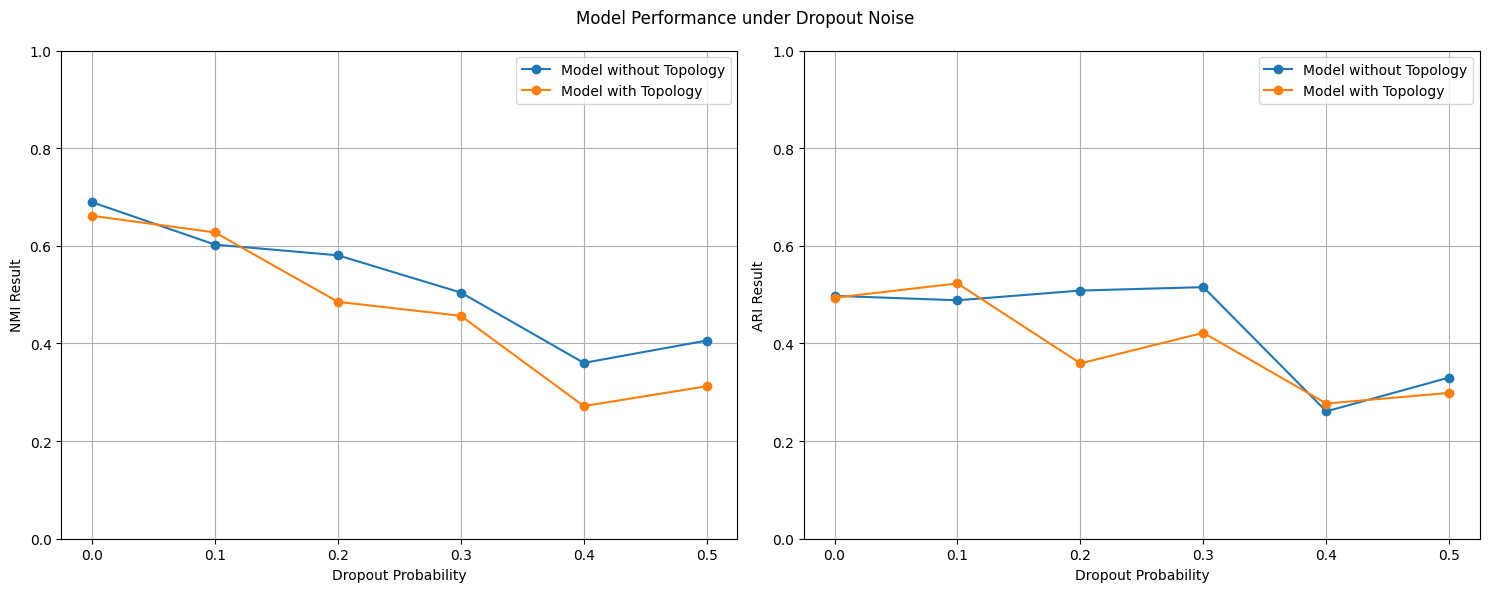

In [ ]:
from utils.perturbation import dropout_event

# Testing with dropout_event first
drop_prob = np.arange(0, 0.6, 0.1)

nmi_scores_1 = []
ari_scores_1 = []

nmi_scores_2 = []
ari_scores_2 = []

for prob in drop_prob:
    x_noisy = dropout_event(torch.from_numpy(gene_exp), prob).numpy()

    nmi_1, ari_1 = eval_model_with_X(x_noisy, use_topo=False)
    nmi_2, ari_2 = eval_model_with_X(x_noisy, use_topo=True)

    nmi_scores_1.append(nmi_1)
    ari_scores_1.append(ari_1)
    nmi_scores_2.append(nmi_2)
    ari_scores_2.append(ari_2)
    print(f"Dropout Noise Level: {prob:.2f} | Model 1 NMI: {nmi_1:.4f} | Model 1 ARI: {ari_1:.4f} | Model 2 NMI: {nmi_2:.4f} | Model 2 ARI: {ari_2:.4f}")

print("NMI Scores without Topo:", nmi_scores_1)
print("NMI Scores with Topo:", nmi_scores_2)
print("ARI Scores without Topo:", ari_scores_1)
print("ARI Scores with Topo:", ari_scores_2)

import matplotlib.pyplot as plt

plt.figure(figsize=(15, 6))

plt.subplot(1, 2, 1)
plt.plot(drop_prob, nmi_scores_1, marker='o', label='Base')
plt.plot(drop_prob, nmi_scores_2, marker='o', label='Topo')
plt.xlabel('Dropout Probability')
plt.ylabel('NMI Result')
plt.ylim(0, 1)
plt.legend()
plt.grid()

plt.subplot(1, 2, 2)
plt.plot(drop_prob, ari_scores_1, marker='o', label='Base')
plt.plot(drop_prob, ari_scores_2, marker='o', label='Topo')
plt.xlabel('Dropout Probability')
plt.ylabel('ARI Result')
plt.ylim(0, 1)
plt.legend()
plt.grid()

plt.suptitle('Model Performance under Dropout Noise')
plt.tight_layout()
plt.savefig(f'scCCL_{dataset}_dropout_noise_evaluation.png')
plt.show()

### B. Testing robustness with Gaussian noise in `X_data`

Epoch 1/2: Loss: 93.8039, Topo: 0.000, Instance: 65.5973, Cluster: 28.2066

--- Final Epoch 2 Results ---
ARI: 0.3799, NMI: 0.5832
Epoch 1/2: Loss: 93.8039, Topo: 0.000, Instance: 65.5973, Cluster: 28.2066

--- Final Epoch 2 Results ---
ARI: 0.5545, NMI: 0.6625
Gaussian Noise Mean: 0.00 | Model 1 NMI: 0.5832 | Model 1 ARI: 0.3799 | Model 2 NMI: 0.6625 | Model 2 ARI: 0.5545
Epoch 1/2: Loss: 93.1643, Topo: 0.000, Instance: 65.3917, Cluster: 27.7726

--- Final Epoch 2 Results ---
ARI: 0.4384, NMI: 0.6044
Epoch 1/2: Loss: 93.1643, Topo: 0.000, Instance: 65.3917, Cluster: 27.7726

--- Final Epoch 2 Results ---
ARI: 0.3807, NMI: 0.5669
Gaussian Noise Mean: 0.10 | Model 1 NMI: 0.6044 | Model 1 ARI: 0.4384 | Model 2 NMI: 0.5669 | Model 2 ARI: 0.3807
Epoch 1/2: Loss: 94.6020, Topo: 0.000, Instance: 66.0815, Cluster: 28.5205

--- Final Epoch 2 Results ---
ARI: 0.4678, NMI: 0.6307
Epoch 1/2: Loss: 94.6020, Topo: 0.000, Instance: 66.0815, Cluster: 28.5205

--- Final Epoch 2 Results ---
ARI: 0.4953

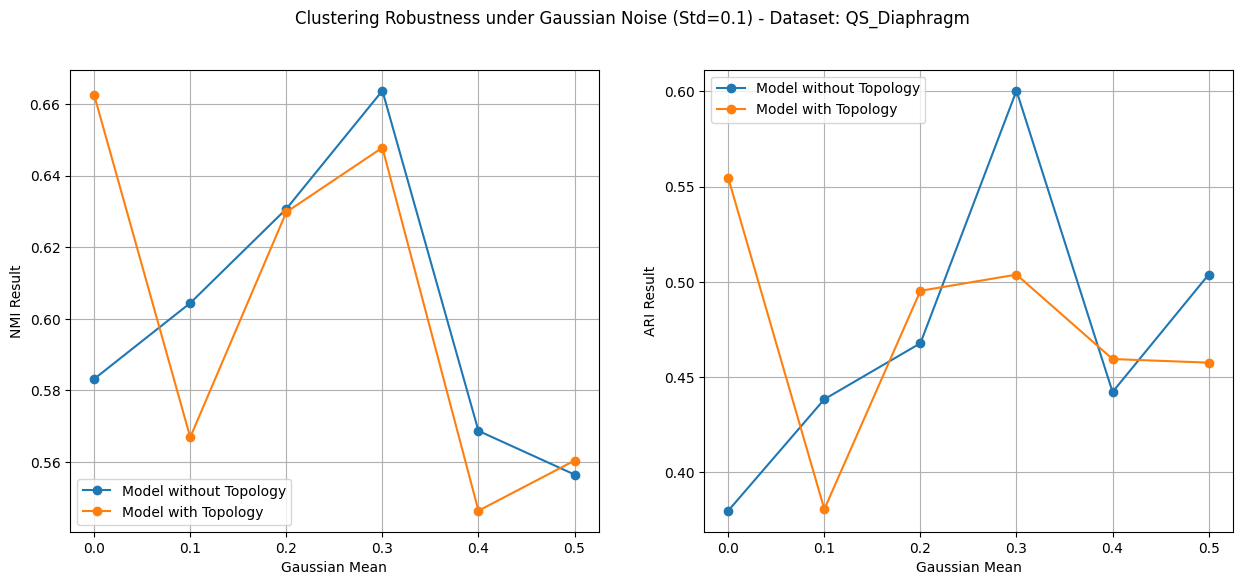

In [ ]:
from utils.perturbation import gaussian_noise_event

# Testing with dropout_event first
STD_GAUSSIAN = 0.1
gaussian_mean = np.arange(0, 0.6, 0.1)

nmi_scores_1 = []
ari_scores_1 = []
nmi_scores_2 = []
ari_scores_2 = []

for mean in gaussian_mean:
    x_noisy = gaussian_noise_event(torch.from_numpy(gene_exp), mean, std=0.1).numpy()
    nmi_1, ari_1 = eval_model_with_X(x_noisy, use_topo=False)
    nmi_2, ari_2 = eval_model_with_X(x_noisy, use_topo=True)
    nmi_scores_1.append(nmi_1)
    ari_scores_1.append(ari_1)
    nmi_scores_2.append(nmi_2)
    ari_scores_2.append(ari_2)
    print(f"Gaussian Noise Mean: {mean:.2f} | Model 1 NMI: {nmi_1:.4f} | Model 1 ARI: {ari_1:.4f} | Model 2 NMI: {nmi_2:.4f} | Model 2 ARI: {ari_2:.4f}")

print("NMI Scores without Topo:", nmi_scores_1)
print("NMI Scores with Topo:", nmi_scores_2)
print("ARI Scores without Topo:", ari_scores_1)
print("ARI Scores with Topo:", ari_scores_2)

import matplotlib.pyplot as plt

plt.figure(figsize=(15, 6))

plt.subplot(1, 2, 1)
plt.plot(gaussian_mean, nmi_scores_1, marker='o', label='Base')
plt.plot(gaussian_mean, nmi_scores_2, marker='o', label='Topo')
plt.xlabel('Gaussian Mean')
plt.ylabel('NMI Result')
plt.ylim(0, 1)
plt.legend()
plt.grid()

plt.subplot(1, 2, 2)
plt.plot(gaussian_mean, ari_scores_1, marker='o', label='Base')
plt.plot(gaussian_mean, ari_scores_2, marker='o', label='Topo')
plt.xlabel('Gaussian Mean')
plt.ylabel('ARI Result')
plt.ylim(0, 1)
plt.legend()
plt.grid()

plt.suptitle(f'Clustering Robustness under Gaussian Noise (Std={STD_GAUSSIAN}) - Dataset: {dataset}')
plt.savefig(f'scCCL_{dataset}_gaussian_noise_evaluation.png')
plt.show()